# Tema 2 Machine Learning - Images Classificator
## Mandescu Victor-Ioan 342C4

In [ ]:
%pip install matplotlib
%pip install Pillow

from PIL import Image
import numpy as np
import os
import matplotlib.pyplot as plt
import random

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
img_path = 'images/imagebits/imagebits/train/1/3.png'
image = Image.open(img_path)
img_array = np.array(image)
print(f"Shape-ul matricei: {img_array.shape}")
image.show()

Shape-ul matricei: (96, 96, 3)


## Exploratory data analysis for image classification - imagebits

Class 1:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 2:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 3:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 4:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 5:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 6:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 7:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 8:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 9:
  Number of images in the training set: 800
  Number of images in the test set: 500
Class 10:
  Number of images in the training set: 800
  Number of images in the test set: 500


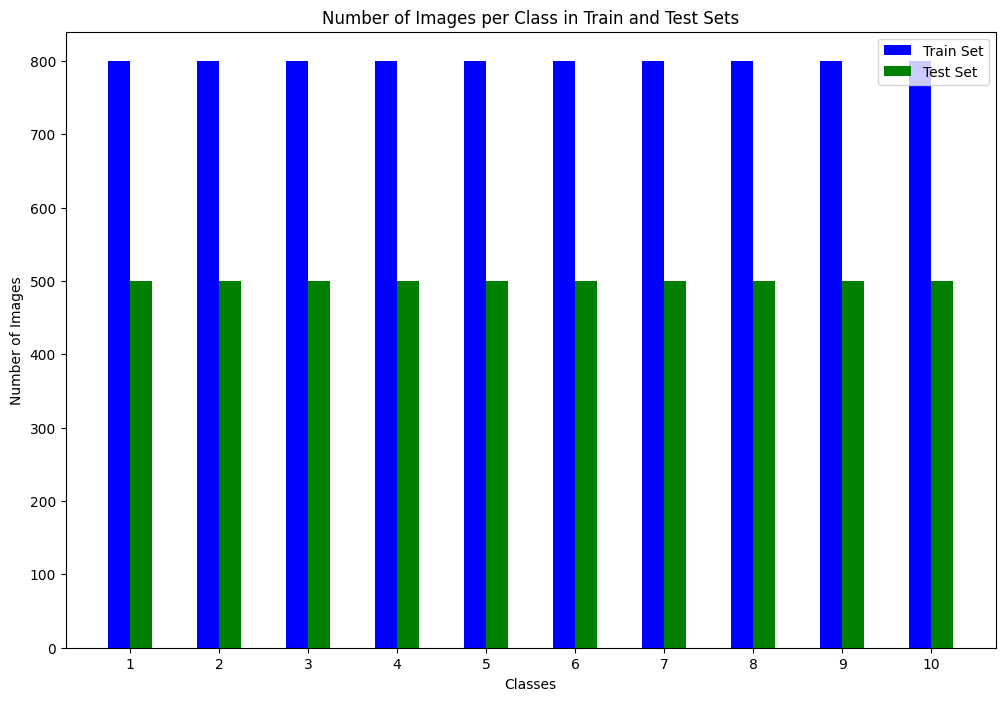

In [3]:
img_train_dir_path = 'images/imagebits/imagebits/train/'
img_test_dir_path = 'images/imagebits/imagebits/test/'
number_classes = {}

for i in range(1, 11):
    train_class_dir = os.path.join(img_train_dir_path, str(i))
    test_class_dir = os.path.join(img_test_dir_path, str(i))
    
    train_images = os.listdir(train_class_dir)
    test_images = os.listdir(test_class_dir)

    number_classes[i] = {
        'train_count': len(train_images),
        'test_count': len(test_images)
    }
    
    print(f"Class {i}:")
    print(f"  Number of images in the training set: {len(train_images)}")
    print(f"  Number of images in the test set: {len(test_images)}")

labels = list(number_classes.keys())
train_vals = [v['train_count'] for v in number_classes.values()]
test_vals = [v['test_count'] for v in number_classes.values()]

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width/2, train_vals, width, label='Train Set', color='blue')
plt.bar(x + width/2, test_vals, width, label='Test Set', color='green')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train and Test Sets')
plt.xticks(x, labels)
plt.legend()
plt.show()

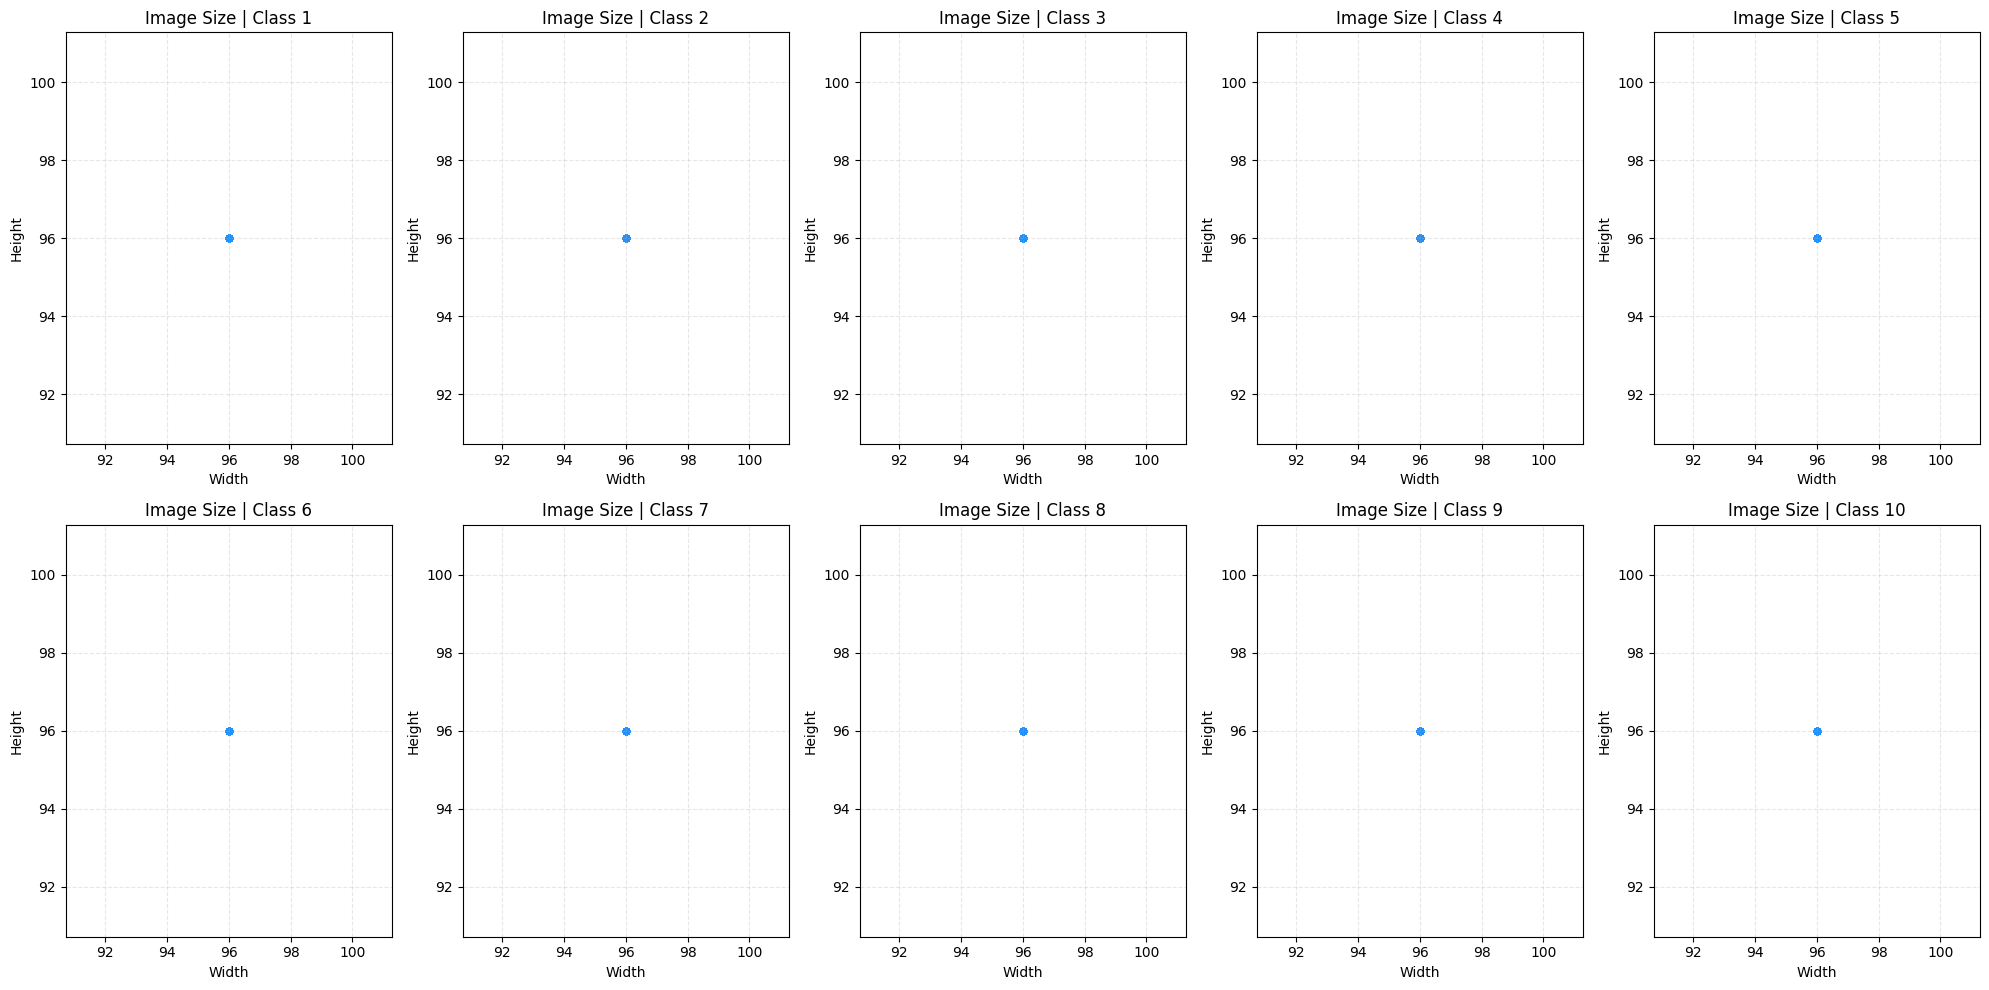

In [ ]:
class_data = {}

for i in range(1, 11):
    class_dir = os.path.join(img_train_dir_path, str(i))
    images = os.listdir(class_dir)
    
    widths = []
    heights = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[i] = {'w': widths, 'h': heights}

fig = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    ax = plt.subplot(2, 5, idx + 1)

    w = class_data[class_id]['w']
    h = class_data[class_id]['h']

    ax.scatter(w, h, alpha=0.5, s=20, color='dodgerblue')
    ax.set_title(f'Image Size | Class {class_id}')
    ax.set_xlabel('Width')
    ax.set_ylabel('Height')
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

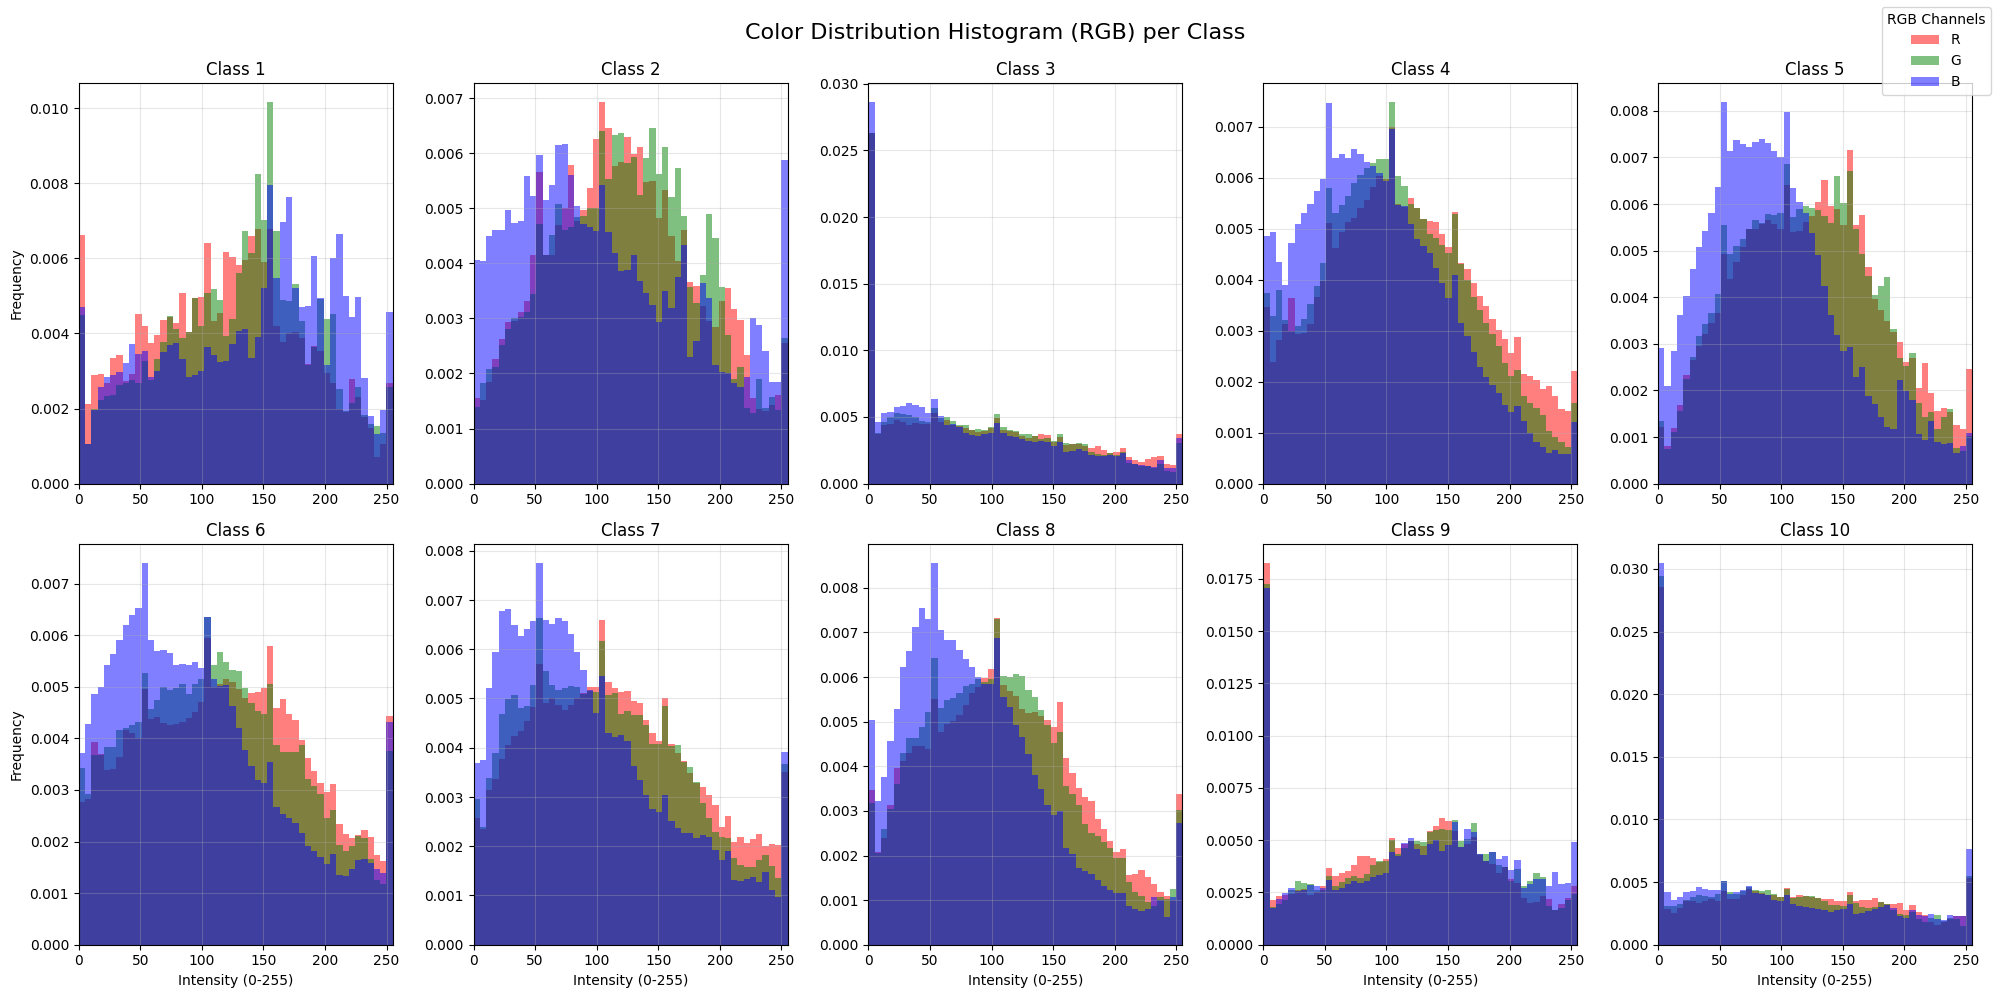

In [12]:
import matplotlib.pyplot as plt
import os
import numpy as np
from PIL import Image

fig, _ = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))
 
    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            try:
                with Image.open(img_path).convert('RGB') as img:
                    img_array = np.array(img)
                    all_reds.extend(img_array[:, :, 0].flatten())
                    all_greens.extend(img_array[:, :, 1].flatten())
                    all_blues.extend(img_array[:, :, 2].flatten())
            except:
                pass

    ax = plt.subplot(2, 5, idx + 1)
    ax.hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax.hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax.hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax.set_title(f'Class {class_id}')
    ax.set_xlim(0, 255)
    
    if idx % 5 == 0:
        ax.set_ylabel('Frequency')
    if idx >= 5:
        ax.set_xlabel('Intensity (0-255)')
        
    ax.grid(True, alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) per Class", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

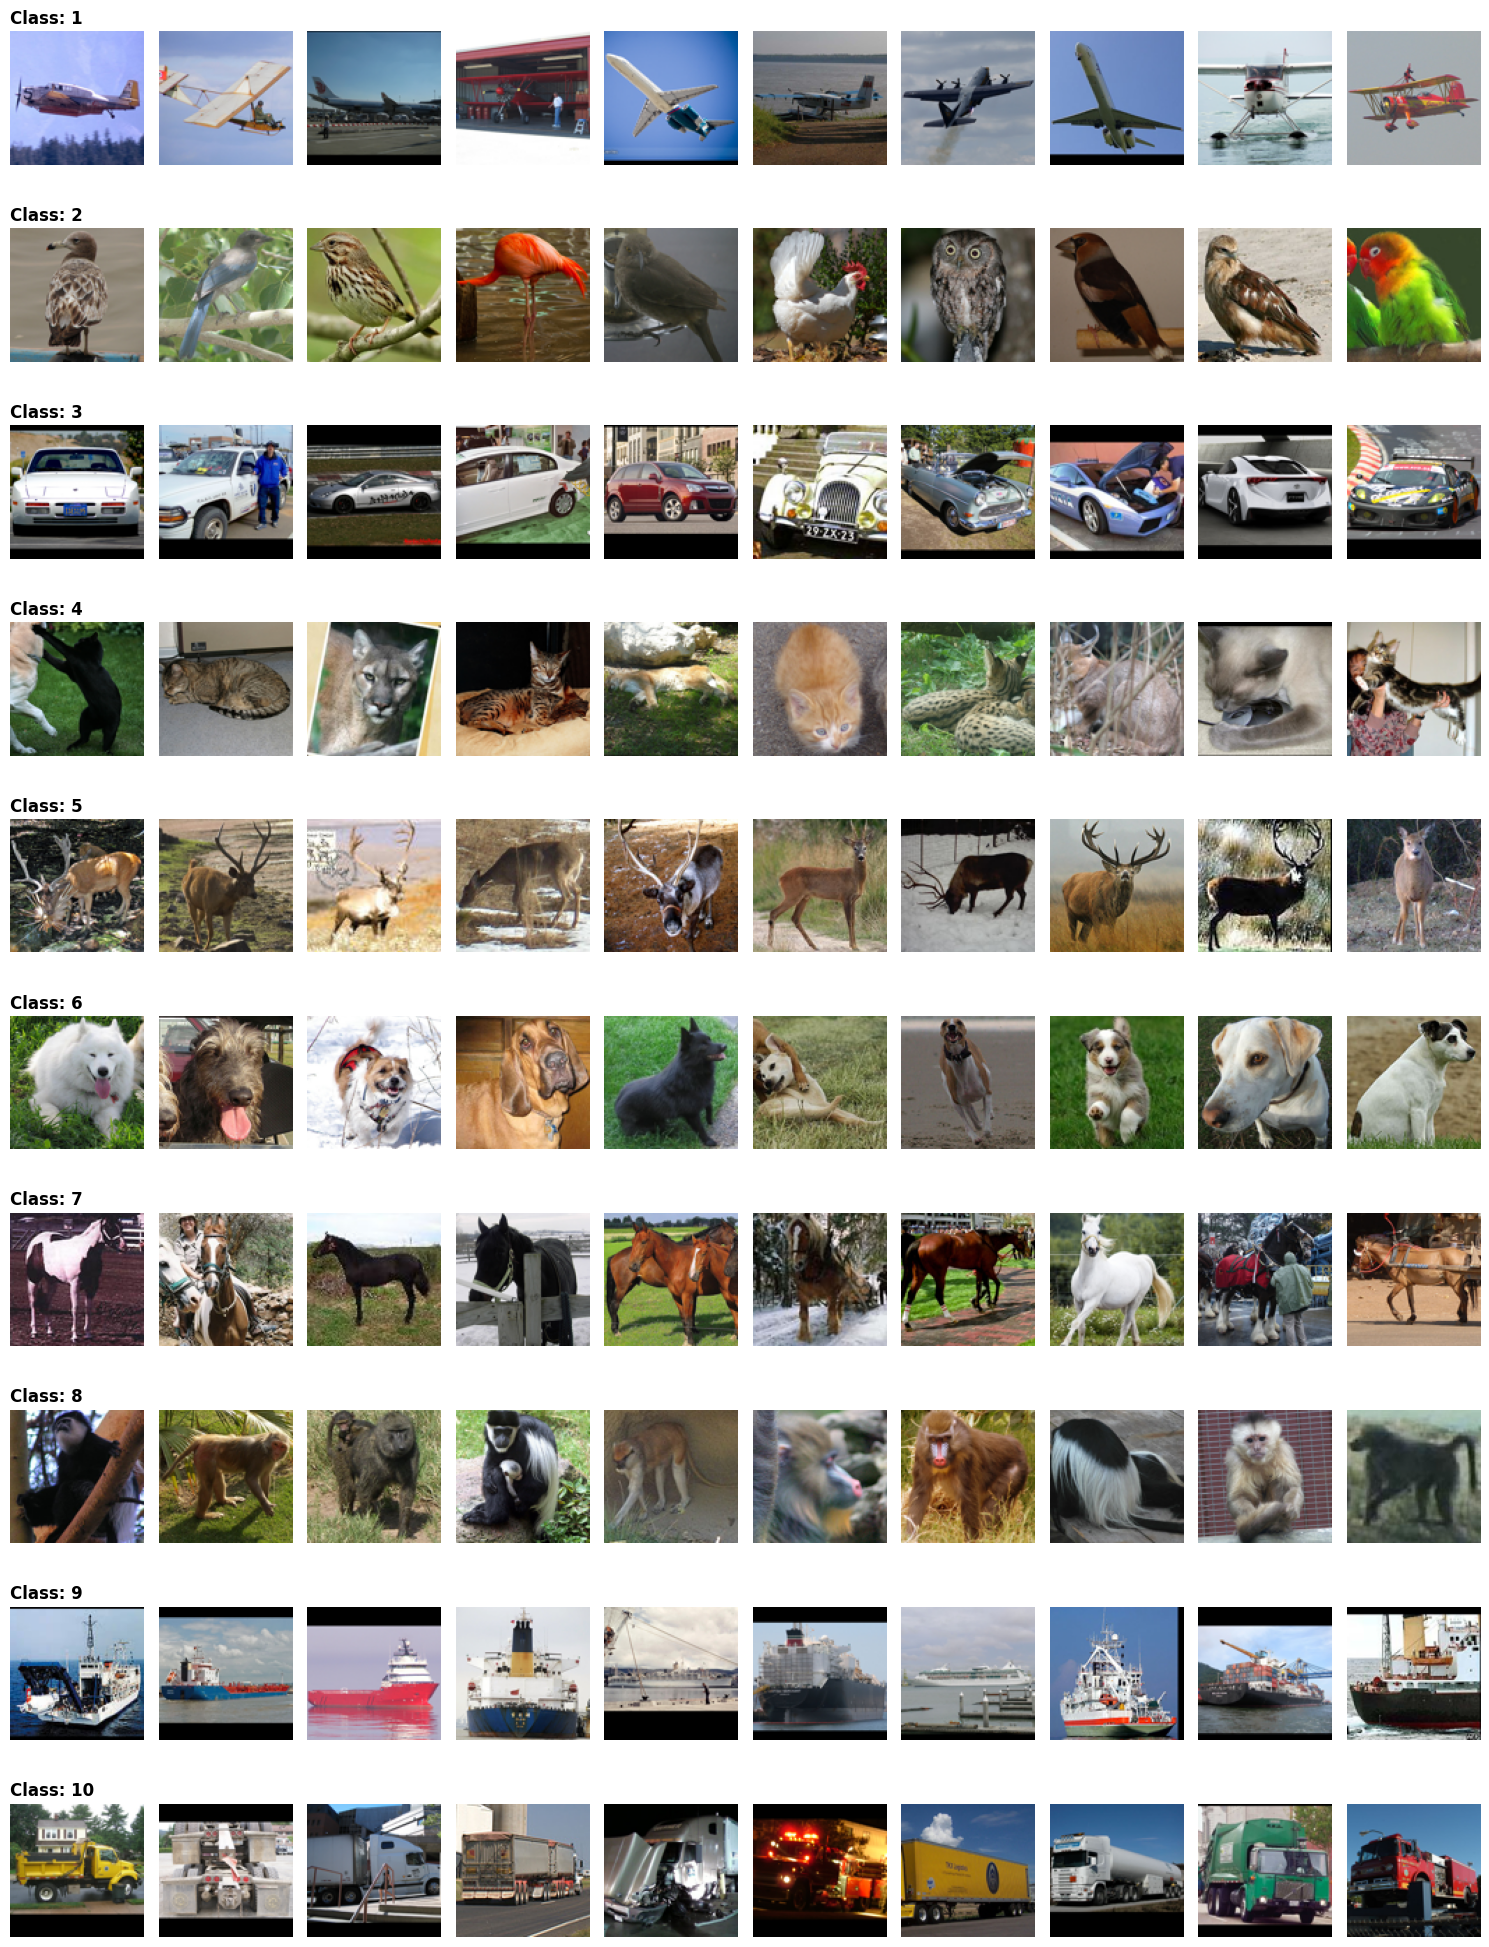

In [13]:
fig, axes = plt.subplots(nrows=len(range(1, 11)), ncols=10, figsize=(15, 20))

for row_idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))   
    all_imgs = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax = axes[row_idx, col_idx]
            ax.imshow(img)
            ax.axis('off')
            
            if col_idx == 0:
                ax.set_title(f'Class: {class_id}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

## Exploratory data analysis for image classification - land_patches

Class 'AnnualCrop': Train=200, Test=700, Val=100
Class 'Forest': Train=200, Test=700, Val=100
Class 'HerbaceousVegetation': Train=200, Test=700, Val=100
Class 'Highway': Train=200, Test=700, Val=100
Class 'Industrial': Train=200, Test=700, Val=100
Class 'Pasture': Train=200, Test=700, Val=100
Class 'PermanentCrop': Train=200, Test=700, Val=100
Class 'Residential': Train=200, Test=700, Val=100
Class 'River': Train=200, Test=700, Val=100
Class 'SeaLake': Train=200, Test=700, Val=100


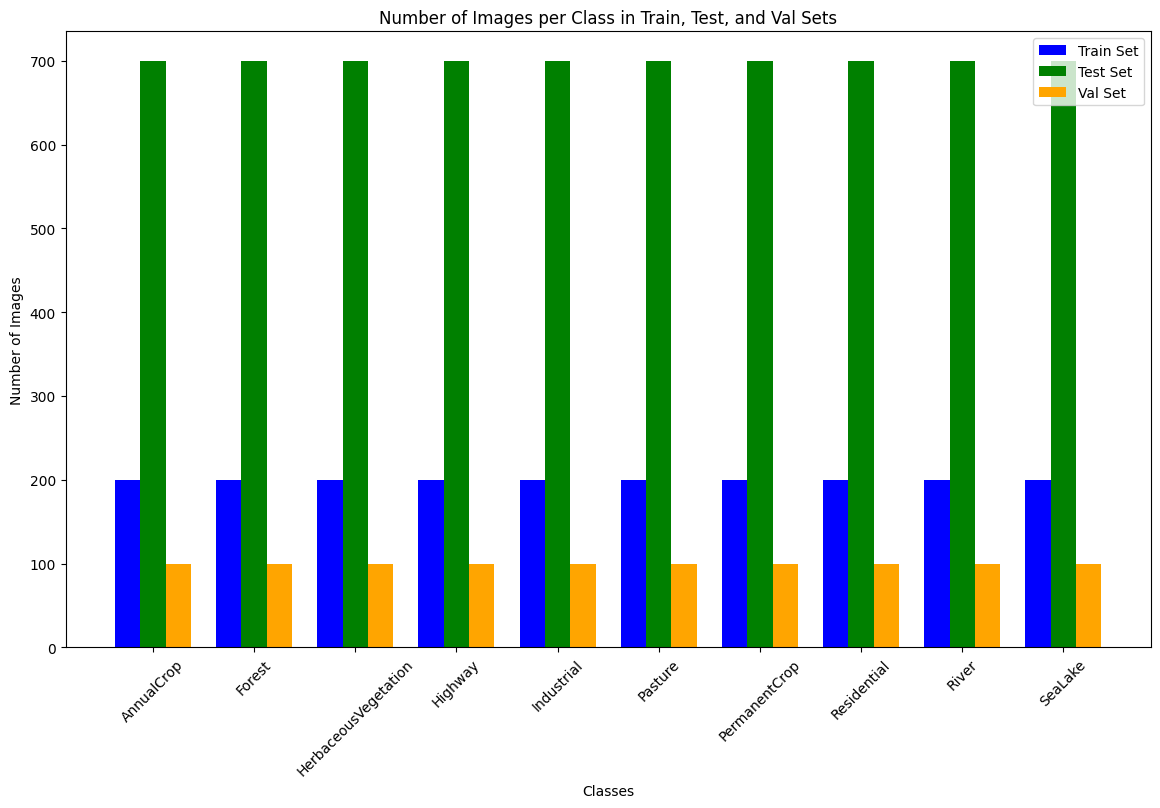

In [ ]:
land_patches_train_dir_path = 'images/land_patches/land_patches/train/'
land_patches_test_dir_path = 'images/land_patches/land_patches/test/'
land_patches_val_dir_path = 'images/land_patches/land_patches/val/'

class_names = [d for d in os.listdir(land_patches_train_dir_path) 
               if os.path.isdir(os.path.join(land_patches_train_dir_path, d))]
class_names.sort()

number_classes = {}
for class_name in class_names:
    train_class_dir = os.path.join(land_patches_train_dir_path, class_name)
    test_class_dir = os.path.join(land_patches_test_dir_path, class_name)
    val_class_dir = os.path.join(land_patches_val_dir_path, class_name)
    
    train_count = len(os.listdir(train_class_dir))
    test_count = len(os.listdir(test_class_dir))
    val_count = len(os.listdir(val_class_dir))

    number_classes[class_name] = {
        'train_count': train_count,
        'test_count': test_count,
        'val_count': val_count
    }
    
    print(f"Class '{class_name}': Train={train_count}, Test={test_count}, Val={val_count}")

labels = list(number_classes.keys())
train_vals = [v['train_count'] for v in number_classes.values()]
test_vals = [v['test_count'] for v in number_classes.values()]
val_vals = [v['val_count'] for v in number_classes.values()]

x = np.arange(len(labels))
width = 0.25 

fig = plt.subplots(figsize=(14, 8))
plt.bar(x - width, train_vals, width, label='Train Set', color='blue')
plt.bar(x, test_vals, width, label='Test Set', color='green')
plt.bar(x + width, val_vals, width, label='Val Set', color='orange')
plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train, Test, and Val Sets')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()

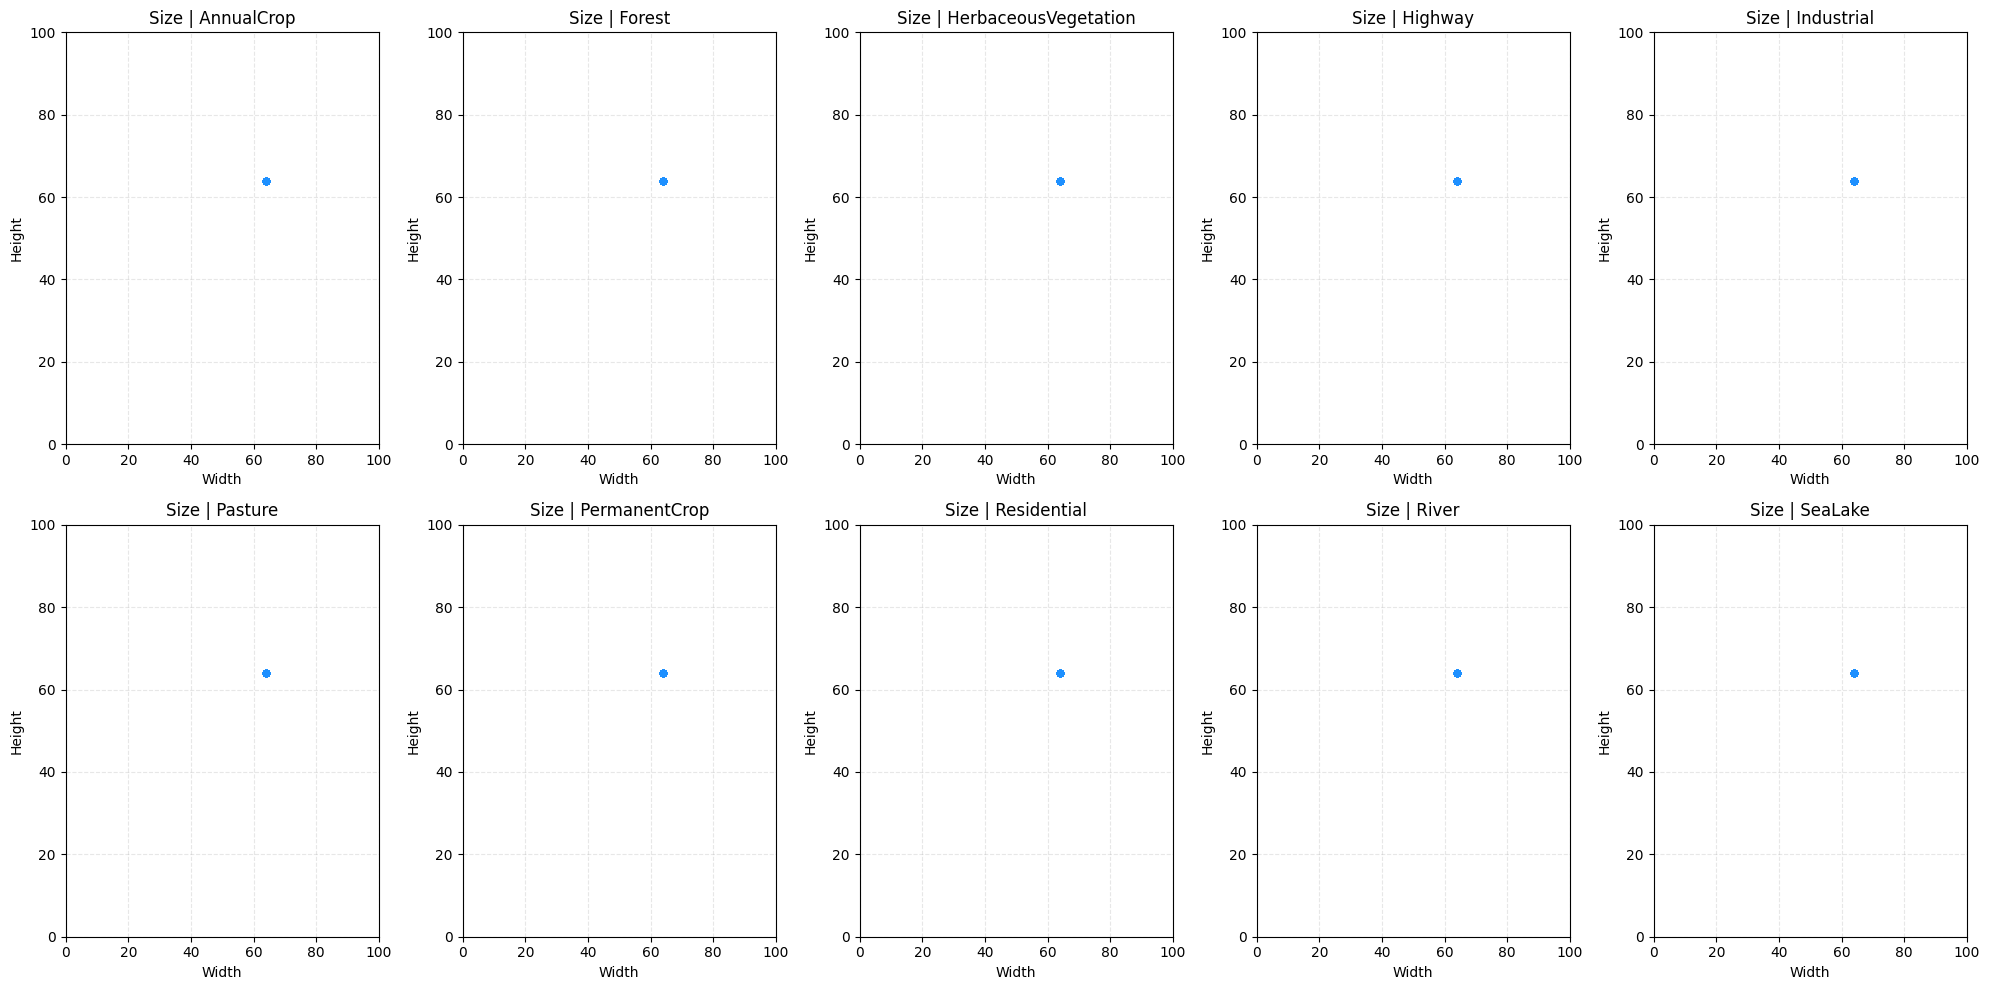

In [21]:
class_data = {}
for class_name in class_names:
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    images = os.listdir(class_dir)
    
    widths = []
    heights = []
    
    for img_name in images:
        if img_name.lower().endswith(('.png', '.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[class_name] = {'w': widths, 'h': heights}


fig = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):
    ax = plt.subplot(2, 5, idx + 1)

    w = class_data[class_name]['w']
    h = class_data[class_name]['h']

    ax.scatter(w, h, alpha=0.5, s=20, color='dodgerblue')
    
    ax.set_title(f'Size | {class_name}')
    ax.set_xlabel('Width')
    ax.set_ylabel('Height')
    
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()